In this Notebook, i will follow the steps and code suggestions represented by: Hands-On Machine Learning with Scikit-Learn and TensorFlow by Aurélien Géron (O'Reilly). Copyright 2017 Aurélien Géron 978-1-491-96229-9

Since i'm working on the Student Performance, i will re-use the same data, to follow the steps suggested in the book.

In [1]:
%store -r df
df


,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10


before steps ....

In [2]:
df.describe()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,1.568567,1.930663,0.221880,3.930663,3.180277,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,0.748660,0.829510,0.593235,0.955717,1.051093,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,2.000000,2.000000,0.000000,5.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


#### Chapter 2:End to End Machine learning Project

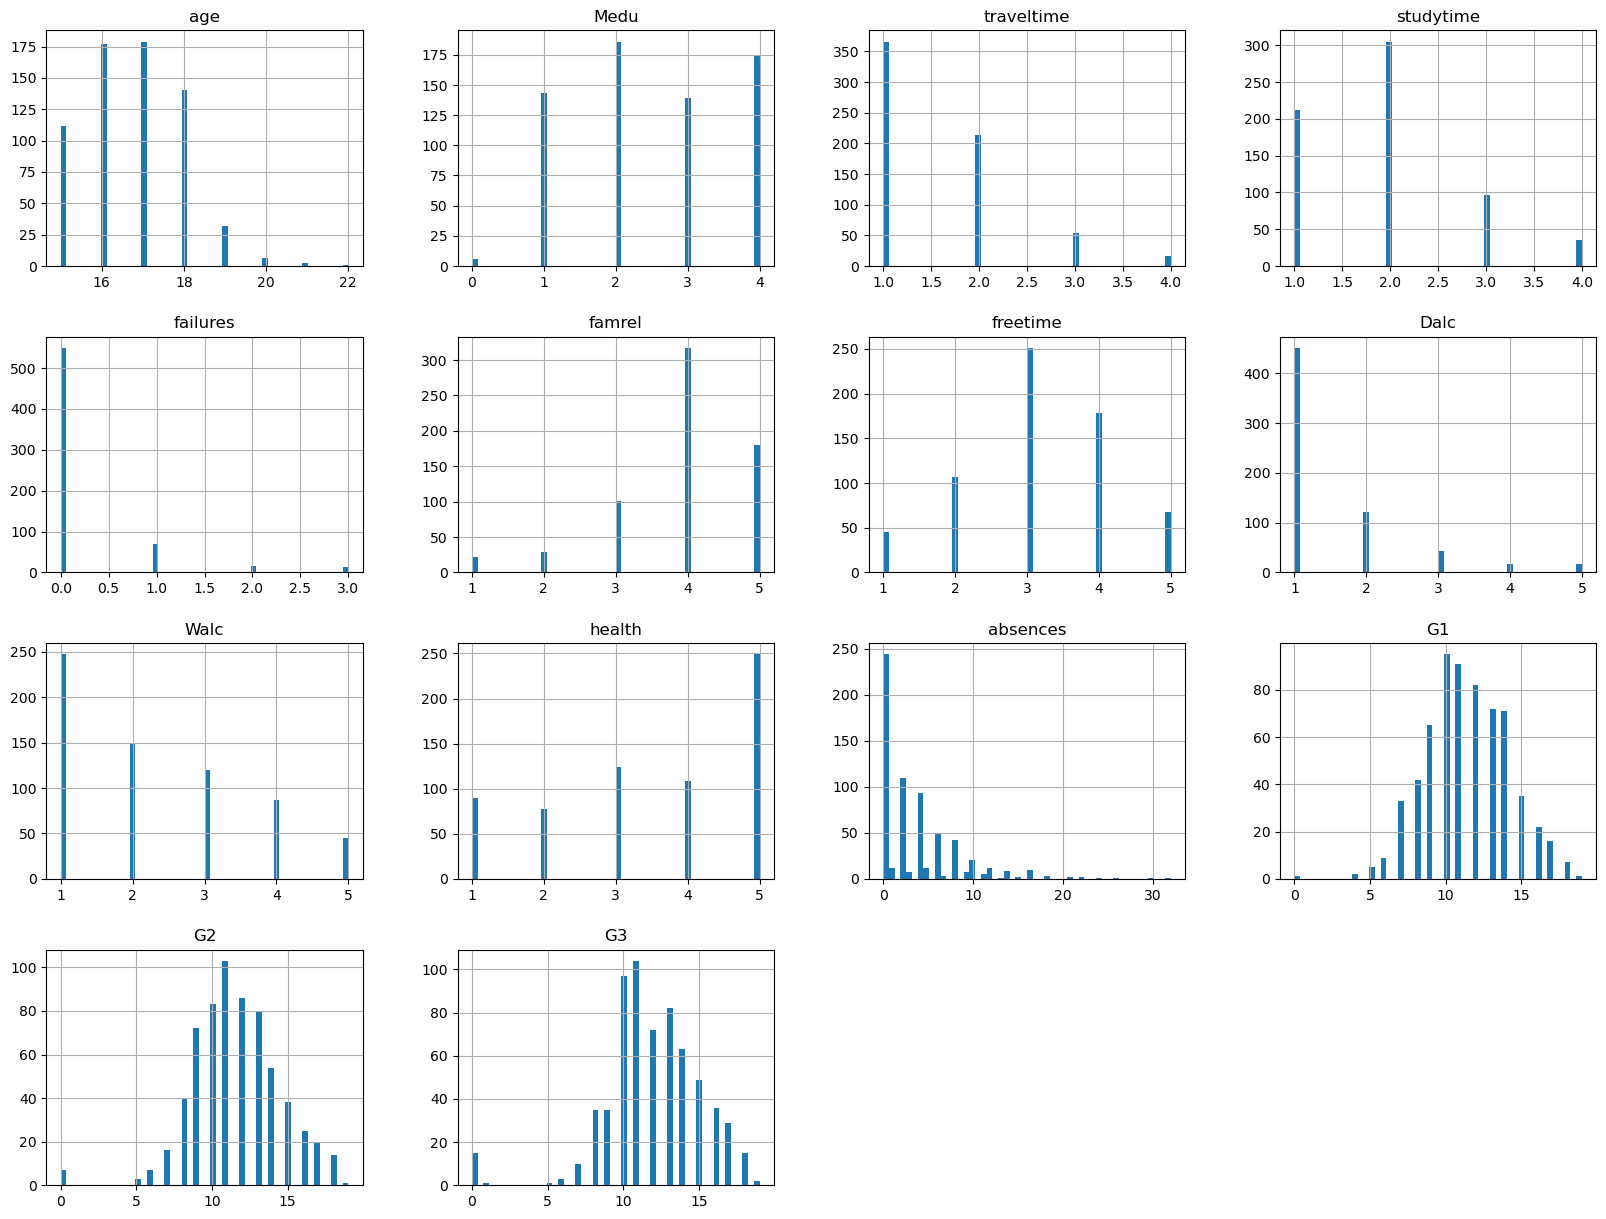

In [3]:
import matplotlib.pyplot as plt 

df.hist(bins = 50, figsize = (20,15))
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

In [5]:

corr_matrix = df.corr(numeric_only=True)

In [6]:
corr_matrix["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
famrel        0.063361
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

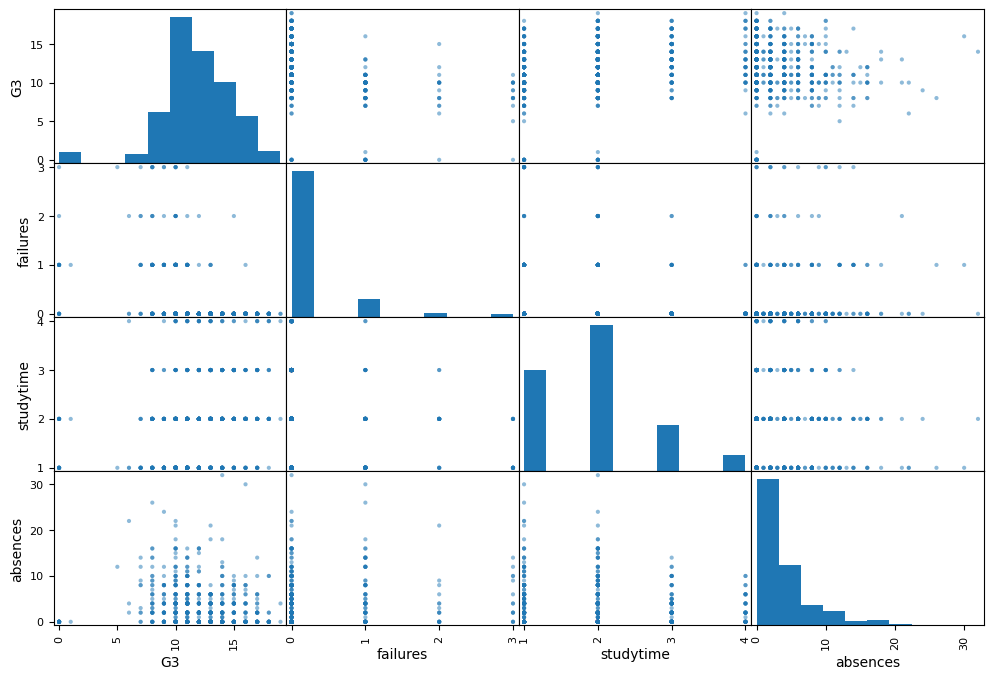

In [7]:
from pandas.plotting import scatter_matrix

attributes = ["G3", "failures", "studytime",
              "absences"]
scatter_matrix(df[attributes], figsize=(12, 8))
plt.show()

In [8]:
from sklearn.svm import SVR

In [9]:
X = df.drop(columns=["G3","G2", "G1"])
y = df["G3"]


In [10]:
import pandas as pd

X_encoded = pd.get_dummies(X, columns=['school', 'reason', 'nursery', 'higher', 'internet'])
X_encoded.head()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,...,reason_course,reason_home,reason_other,reason_reputation,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes
0,18,4,2,2,0,4,3,1,1,3,...,True,False,False,False,False,True,False,True,True,False
1,17,1,1,2,0,5,3,1,1,3,...,True,False,False,False,True,False,False,True,False,True
2,15,1,1,2,0,4,3,2,3,3,...,False,False,True,False,False,True,False,True,False,True
3,15,4,1,3,0,3,2,1,1,5,...,False,True,False,False,False,True,False,True,False,True
4,16,3,1,2,0,4,3,1,2,5,...,False,True,False,False,False,True,False,True,True,False


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=0)


### Support vector Regressor

From what i understood, instead of scaling and then fitting a model, we can do both at the same time using scikitlearn pipeline.
And for the test set to be safe from being fitted to the model accedently.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),   
    ('model', SVR(kernel='rbf'))      
])

svr_pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0


In [13]:
svr_predictions = svr_pipeline.predict(X_test)

In [14]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import numpy as np
train_preds = svr_pipeline.predict(X_train)
test_preds = svr_pipeline.predict(X_test)

train_rmse = np.sqrt(root_mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(root_mean_squared_error(y_test, test_preds))

print('Train SVR RMSE:', train_rmse)
print('Test SVR RMSE:', test_rmse)

Train SVR RMSE: 1.576626968768394
Test SVR RMSE: 1.62578302621833


fair! but needs optimization

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

param_grid = [
    {
        'model__kernel': ['rbf'], 
        'model__C': [1.0, 3.0, 10., 30., 100., 300., 1000.0],
        'model__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
    }
]

grid_search = GridSearchCV(
    svr_pipeline, 
    param_grid, 
    cv=3,
    scoring='neg_root_mean_squared_error'
)

grid_search.fit(X_train, y_train)

,estimator,"Pipeline(step...del', SVR())])"
,param_grid,"[{'model__C': [1.0, 3.0, ...], 'model__gamma': [0.01, 0.03, ...], 'model__kernel': ['rbf']}]"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [16]:
grid_search.best_params_

{'model__C': 3.0, 'model__gamma': 0.01, 'model__kernel': 'rbf'}

In [17]:
final_svr_pipeline = grid_search.best_estimator_
final_svr_pipeline.fit(X_train, y_train)
preds = final_svr_pipeline.predict(X_test)

In [19]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import numpy as np
train_preds = final_svr_pipeline.predict(X_train)
test_preds = final_svr_pipeline.predict(X_test)

train_rmse = np.sqrt(root_mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(root_mean_squared_error(y_test, test_preds))

print('Train SVR RMSE:', train_rmse)
print('Test SVR RMSE:', test_rmse)

Train SVR RMSE: 1.6092707075359043
Test SVR RMSE: 1.6277239705787154


The model indeed got optimized, but not really, the results remain almost the same

#### Classification

In this chapter i will use the SciKitlearn open dataset MNIST

In [21]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)

In [22]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [23]:
X, y = mnist["data"], mnist["target"]

In [24]:
X.shape


(70000, 784)

In [26]:
y.shape

(70000,)

In [27]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [29]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_train)


,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [30]:
from sklearn.model_selection import cross_val_score
cross_val_score(knn_clf, X_train, y_train, cv=5, scoring="accuracy")

array([0.96975   , 0.97016667, 0.96933333, 0.96816667, 0.969     ])

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

y_train_pred = cross_val_predict(knn_clf, X_train, y_train, cv=5)

cm = confusion_matrix(y_train, y_train_pred)
cm

array([[5883,    3,    5,    0,    1,    6,   16,    2,    2,    5],
       [   1, 6710,    8,    1,    2,    0,    3,   14,    1,    2],
       [  40,   60, 5713,   13,    8,    4,   10,   83,   18,    9],
       [   8,   15,   40, 5920,    1,   54,    3,   33,   34,   23],
       [   3,   52,    2,    1, 5639,    0,   14,   12,    1,  118],
       [  16,   13,    4,   75,    5, 5208,   64,    8,    5,   23],
       [  26,   13,    2,    0,    7,   21, 5848,    0,    1,    0],
       [   3,   68,   15,    2,   14,    1,    0, 6092,    3,   67],
       [  20,   72,   16,   85,   30,   95,   26,   18, 5429,   60],
       [  18,   11,    5,   40,   58,   11,    3,   78,   10, 5715]])

In [34]:
from scipy.ndimage import shift

In [35]:
def shift_image(image, dx, dy):
    image = image.reshape((28, 28))
    shifted_image = shift(image, [dy, dx], cval=0, mode="constant")
    return shifted_image.reshape([-1])

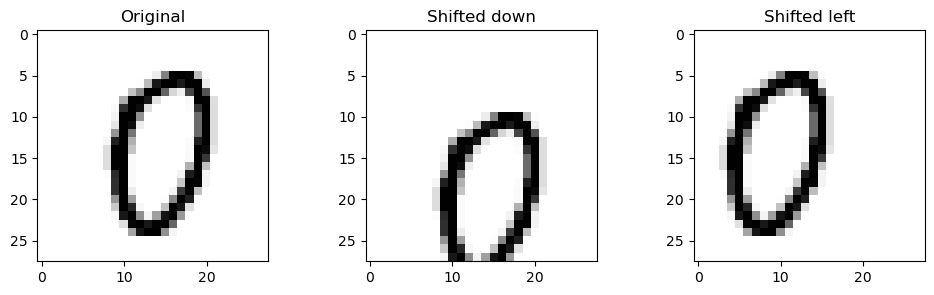

In [36]:
image = X_train[1000]  
shifted_image_down = shift_image(image, 0, 5)
shifted_image_left = shift_image(image, -5, 0)

plt.figure(figsize=(12, 3))
plt.subplot(131)
plt.title("Original")
plt.imshow(image.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.subplot(132)
plt.title("Shifted down")
plt.imshow(shifted_image_down.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.subplot(133)
plt.title("Shifted left")
plt.imshow(shifted_image_left.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.show()

In [37]:
X_train_augmented = [image for image in X_train]
y_train_augmented = [label for label in y_train]

for dx, dy in ((-1, 0), (1, 0), (0, 1), (0, -1)):
    for image, label in zip(X_train, y_train):
        X_train_augmented.append(shift_image(image, dx, dy))
        y_train_augmented.append(label)

X_train_augmented = np.array(X_train_augmented)
y_train_augmented = np.array(y_train_augmented)

In [38]:
shuffle_idx = np.random.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_idx]
y_train_augmented = y_train_augmented[shuffle_idx]

In [39]:
from sklearn.model_selection import GridSearchCV

param_grid = [{'weights': ["uniform", "distance"], 'n_neighbors': [3, 4, 5, 6]}]

knn_clf = KNeighborsClassifier()
grid_search = GridSearchCV(knn_clf, param_grid, cv=5)
grid_search.fit(X_train[:10_000], y_train[:10_000])
grid_search.best_params_

{'n_neighbors': 4, 'weights': 'distance'}

In [40]:
knn_clf = KNeighborsClassifier(**grid_search.best_params_)
knn_clf.fit(X_train_augmented, y_train_augmented)
augmented_accuracy = knn_clf.score(X_test, y_test)
augmented_accuracy

0.9763

The rest of classification tasks are already applied on Performance_prediction.ipynb notebook.

Chapter 6: SVMs 

Question 9: Train an SVM classifier on the MNIST dataset. Since SVM classifiers are binary
classifiers, you will need to use one-versus-all to classify all 10 digits. 

In [1]:
from sklearn.svm import SVC

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist["data"], mnist["target"]
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=42))
])

param_grid = {
    'svc__kernel': ['rbf'],
    'svc__C': [1, 5, 10],
    'svc__gamma': ['scale', 0.001, 0.005, 0.01],
}

grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

X_sub, y_sub = X_train[:2000], y_train[:2000]
grid_search.fit(X_sub, y_sub)

print("Best params:", grid_search.best_params_)
print("Best CV accuracy on subset:", grid_search.best_score_)

Best params: {'svc__C': 5, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'}
Best CV accuracy on subset: 0.8800126963545254


In [4]:
from sklearn.metrics import accuracy_score

best_C = grid_search.best_params_['svc__C']
best_gamma = grid_search.best_params_['svc__gamma']

final_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=best_C, gamma=best_gamma, random_state=42))
])

final_pipe.fit(X_train, y_train)

y_test_pred = final_pipe.predict(X_test)
print("Final test accuracy:", accuracy_score(y_test, y_test_pred))

Final test accuracy: 0.973


This is chapter 7: Ensemble Methods

In [1]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist["data"], mnist["target"]

X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:60000], y[50000:60000]
X_test, y_test = X[60000:], y[60000:]

In [2]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
et_clf = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)

rf_clf.fit(X_train, y_train)
et_clf.fit(X_train, y_train)

rf_val_pred = rf_clf.predict(X_val)
et_val_pred = et_clf.predict(X_val)

print('RF Validation Accuracy',accuracy_score(y_val, rf_val_pred))
print('ET Validation Accuracy', accuracy_score(y_val, et_val_pred))

RF Validation Accuracy 0.9736
ET Validation Accuracy 0.9743


In [3]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
        ("et", ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ],
    voting="soft",
    n_jobs=-1,
)

voting_clf.fit(X_train, y_train)
voting_val_pred = voting_clf.predict(X_val)

print('Voting Ensemble Validation Accuracy:', accuracy_score(y_val, voting_val_pred))

Voting Ensemble Validation Accuracy: 0.9749


In [4]:
voting_test_pred = voting_clf.predict(X_test)

print('RF Test Accuracy:',accuracy_score(y_test, rf_clf.predict(X_test)))
print('ET Test Accuracy:',accuracy_score(y_test, et_clf.predict(X_test)))
print('Voting Ensemble Test Accuracy:',accuracy_score(y_test, voting_test_pred))

RF Test Accuracy: 0.968
ET Test Accuracy: 0.9703
Voting Ensemble Test Accuracy: 0.9698


Combining the models indeed increases the accuracy, in this case not too impressive because i didn't fit an SVM and other models, it takes so long even when setting parameters to help things speed up!

In [5]:
import numpy as np

rf_val_pred = rf_clf.predict(X_val)
et_val_pred = et_clf.predict(X_val)
X_val_blender = np.column_stack([rf_val_pred, et_val_pred])
y_val_blender = y_val

In [6]:
blender = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
blender.fit(X_val_blender, y_val_blender)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [7]:
rf_test_pred = rf_clf.predict(X_test)
et_test_pred = et_clf.predict(X_test)

X_test_blender = np.column_stack([rf_test_pred, et_test_pred])
blender_test_pred = blender.predict(X_test_blender)

print('RF Test Accuracy:',accuracy_score(y_test, rf_test_pred))
print('ET Test Accuracy:',accuracy_score(y_test, et_test_pred))
print('Blender Test Accuracy:',accuracy_score(y_test, blender_test_pred))

RF Test Accuracy: 0.968
ET Test Accuracy: 0.9703
Blender Test Accuracy: 0.9693
